In [3]:
from datasets import load_dataset
import pandas as pd

In [13]:
view1000 = load_dataset("Eathus/cwe_view1000_list_gpt_few_cwe_desc_final_best", split="train")
view1000_df = view1000.to_pandas()

view1003 = load_dataset("Eathus/cwe_view1003_raw_list", split="train")
view1003_df = view1003.to_pandas()

In [14]:
gpt_pred = load_dataset("Eathus/github-issues-vul-detection-gpt-few-results-final-best2", split="test")
gpt_pred_df = gpt_pred.to_pandas()
gpt_pred_df = gpt_pred_df[~gpt_pred_df.duplicated(subset="issue_github_id", keep=False)]

In [5]:
true_pos = gpt_pred_df[gpt_pred_df.gpt_is_relevant & ~gpt_pred_df.cve_id.isna()]
false_pos = gpt_pred_df[gpt_pred_df.gpt_is_relevant & gpt_pred_df.cve_id.isna()]
false_neg = gpt_pred_df[~gpt_pred_df.gpt_is_relevant & ~gpt_pred_df.cve_id.isna()]
all_true = gpt_pred_df[~gpt_pred_df.cve_id.isna()]

print("true pos:", len(true_pos))
print("false pos:", len(false_pos))
print("false neg:", len(false_neg))
print("all true:", len(all_true))
print("all", len(gpt_pred_df))  

true pos: 296
false pos: 305
false neg: 10
all true: 306
all 1763


In [6]:
# Load both splits
ds = load_dataset(
    "Eathus/github-issues-vul-max-detection-gpt-few-results-final3",
    split=["train", "test"]
)

# ds is now a list: [train_dataset, test_dataset]
train_ds, test_ds = ds

# Convert each to DataFrame
train_df = train_ds.to_pandas()
test_df = test_ds.to_pandas()

# Drop duplicates if needed (like you did for test)
train_df = train_df[~train_df.duplicated(subset="issue_github_id", keep=False)]
test_df = test_df[~test_df.duplicated(subset="issue_github_id", keep=False)]

# Combine both DataFrames
gpt_pred_large_df = pd.concat([train_df, test_df], ignore_index=True)

In [7]:
true_pos_medium = test_df[test_df.gpt_is_relevant & ~test_df.cve_id.isna()]
false_pos_medium = test_df[test_df.gpt_is_relevant & test_df.cve_id.isna()]
false_neg_medium = test_df[~test_df.gpt_is_relevant & ~test_df.cve_id.isna()]
all_true_medium = test_df[~test_df.cve_id.isna()]

print("true pos:", len(true_pos_medium))
print("false pos:", len(false_pos_medium))
print("false neg:", len(false_neg_medium))
print("all true:", len(all_true_medium))
print("all", len(test_df))

true pos: 1264
false pos: 475
false neg: 100
all true: 1364
all 6419


In [ ]:
true_pos_large = gpt_pred_large_df[gpt_pred_large_df.gpt_is_relevant & ~gpt_pred_large_df.cve_id.isna()]
false_pos_large = gpt_pred_large_df[gpt_pred_large_df.gpt_is_relevant & gpt_pred_large_df.cve_id.isna()]
false_neg_large = gpt_pred_large_df[~gpt_pred_large_df.gpt_is_relevant & ~gpt_pred_large_df.cve_id.isna()]
all_true_large = gpt_pred_large_df[~gpt_pred_large_df.cve_id.isna()]

print("true pos:", len(true_pos_large))
print("false pos:", len(false_pos_large))
print("false neg:", len(false_neg_large))
print("all true:", len(all_true_large))
print("all", len(gpt_pred_large_df))

true pos: 3147
false pos: 1157
false neg: 263
all true: 3410
all 16030


In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_cwe_dist(df, k=40, save_path=None, echo=True) :
    data = df[df["cve_primary_cwe"].apply(lambda x: x != None)][
        "cve_primary_cwe"
    ].value_counts(normalize=False)
    data_df = data.head(40).reset_index()
    data_df.columns = ["CWE", "Proportion"]
    print("data len:\t", len(data))
    display(data_df.head(10))
    # Plotting
    plt.figure(figsize=(10, 6))
    sns.barplot(x="CWE", y="Proportion", hue="CWE", data=data_df, palette="viridis")

    # Add labels and title
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Proportion of top {k} CWEs")

    if save_path :
        plt.savefig(
            save_path,
            format='svg',
            bbox_inches='tight',  # Removes extra whitespace
            pad_inches=0,         # Removes padding
            transparent=True      # Optional: removes background
        )
    # Show the plot
    if echo :
        plt.tight_layout()
        plt.show()

In [80]:
import os
def table_to_svg(pretty_table, svg_filename):
    df = pd.DataFrame(pretty_table._rows, columns=pretty_table.field_names)

    # Estimate text width for each column
    col_widths = []
    font_size = 12
    char_width = font_size * 1.4  # average width per character

    for col in df.columns:
        max_len = max([len(str(val)) for val in df[col]] + [len(col)])
        col_widths.append(max_len * char_width)

    total_width = sum(col_widths)
    col_rel_widths = [w / total_width for w in col_widths]

    # Set up figure width/height
    fig_height = 1 + 0.7 * len(df)  # Increased for taller rows
    fig_width = total_width / 100
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis('off')

    # Create table
    mpl_table = ax.table(
        cellText=df.values,
        colLabels=df.columns,
        cellLoc='center',
        loc='center'
    )

    mpl_table.auto_set_font_size(False)
    mpl_table.set_fontsize(font_size)
    mpl_table.scale(1, 2.5)  # Increased vertical scaling for taller rows

    # Style cells
    for (row, col), cell in mpl_table.get_celld().items():
        cell.set_linewidth(0)
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#4a4a4a')
        else:
            cell.set_facecolor('#d5d5d5' if row % 2 == 0 else '#ebebeb')
        cell.set_width(col_rel_widths[col])

    fig.savefig(
            os.path.join('tmp', svg_filename),
            format='svg',
            bbox_inches='tight',  # Removes extra whitespace
            pad_inches=0,         # Removes padding
            transparent=True      # Optional: removes background
        )
    plt.close(fig)

## Small

Number of Samples:			296
Number of CWEs represented:		44
Portion of CWEs in CWE View-1003	97.97%
Portion of unique CWEs in CWE View-1003	86.36%
data len:	 44


,CWE,Proportion
0,476,56
1,787,56
2,89,26
3,401,21
4,125,17
5,617,15
6,120,15
7,770,14
8,416,10
9,119,8


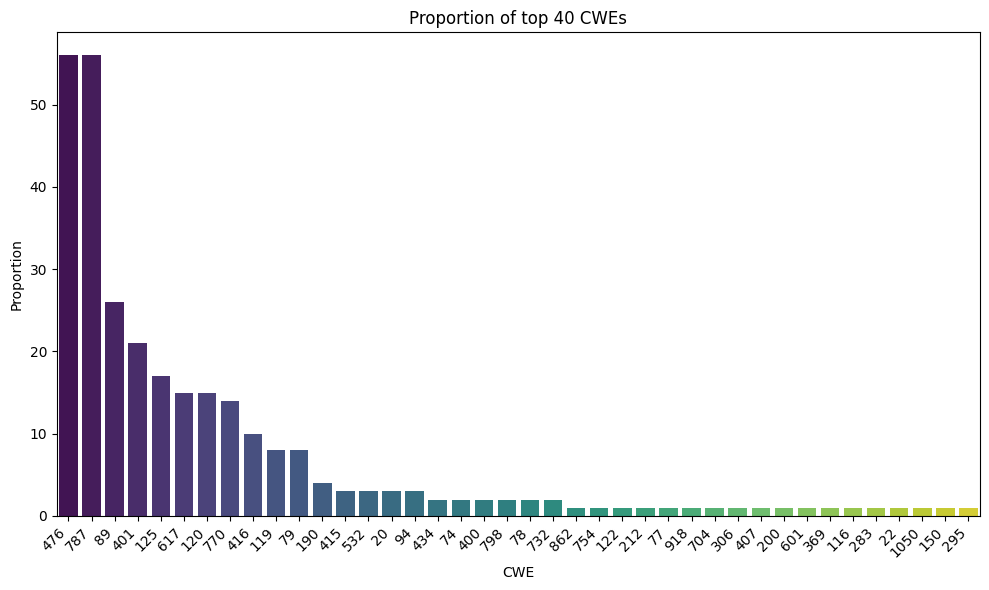

In [61]:
distinct_cwe_count = len(true_pos.cve_primary_cwe.value_counts())
cwe_count = len(true_pos)
in1003 = len(true_pos.loc[true_pos.cve_primary_cwe.isin(view1003_df.ID.tolist())])
unique_in_1003 = len(true_pos.loc[true_pos.cve_primary_cwe.isin(view1003_df.ID.tolist()), 'cve_primary_cwe'].value_counts())
print(f"Number of Samples:\t\t\t{cwe_count}")
print(f"Number of CWEs represented:\t\t{distinct_cwe_count}")
print(f"Portion of CWEs in CWE View-1003\t{100*in1003/cwe_count:.2f}%")
print(f"Portion of unique CWEs in CWE View-1003\t{100*unique_in_1003/distinct_cwe_count:.2f}%")
plot_cwe_dist(true_pos, save_path="tmp/cwe_distribution_small.svg")

## Medium

Number of Samples:			1264
Number of CWEs represented:		109
Portion of CWEs in CWE View-1003	98.42%
Portion of unique CWEs in CWE View-1003	89.91%
data len:	 109


,CWE,Proportion
0,79,229
1,787,138
2,476,100
3,125,66
4,89,58
5,22,43
6,120,38
7,617,34
8,416,28
9,502,27


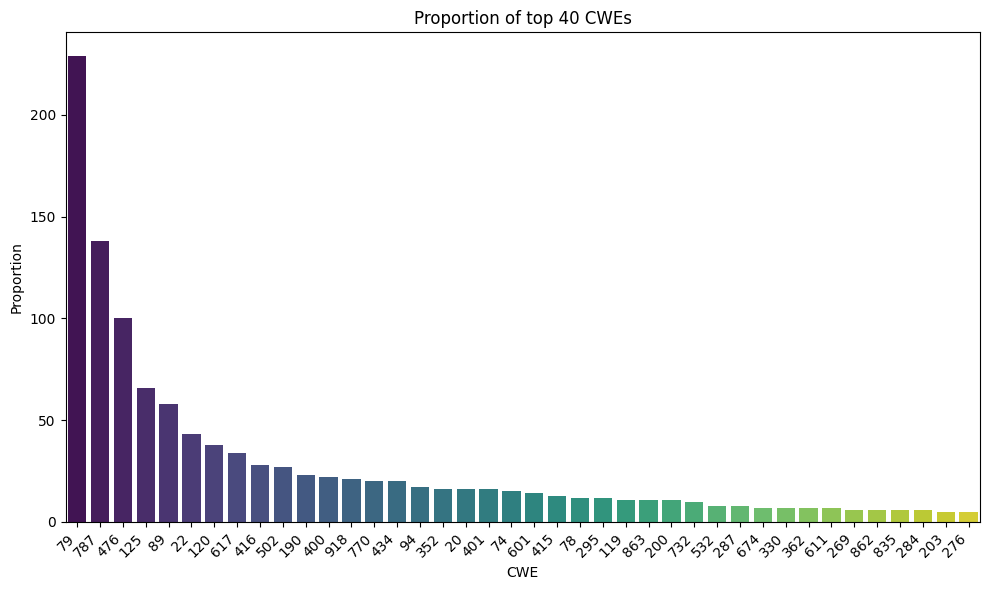

In [62]:
distinct_cwe_count = len(true_pos_medium.cve_primary_cwe.value_counts())
cwe_count = len(true_pos_medium)
in1003 = len(true_pos_medium.loc[true_pos_medium.cve_primary_cwe.isin(view1003_df.ID.tolist())])
unique_in_1003 = len(true_pos_medium.loc[true_pos_medium.cve_primary_cwe.isin(view1003_df.ID.tolist()), 'cve_primary_cwe'].value_counts())
print(f"Number of Samples:\t\t\t{cwe_count}")
print(f"Number of CWEs represented:\t\t{distinct_cwe_count}")
print(f"Portion of CWEs in CWE View-1003\t{100*in1003/cwe_count:.2f}%")
print(f"Portion of unique CWEs in CWE View-1003\t{100*unique_in_1003/distinct_cwe_count:.2f}%")
plot_cwe_dist(true_pos_medium, save_path="tmp/cwe_distribution_medium.svg")

## Large

Number of Samples:			3147
Number of CWEs represented:		148
Portion of CWEs in CWE View-1003	98.16%
Portion of unique CWEs in CWE View-1003	79.73%
data len:	 148


,CWE,Proportion
0,79,507
1,787,369
2,476,233
3,125,185
4,89,150
5,22,105
6,120,103
7,416,75
8,617,71
9,502,71


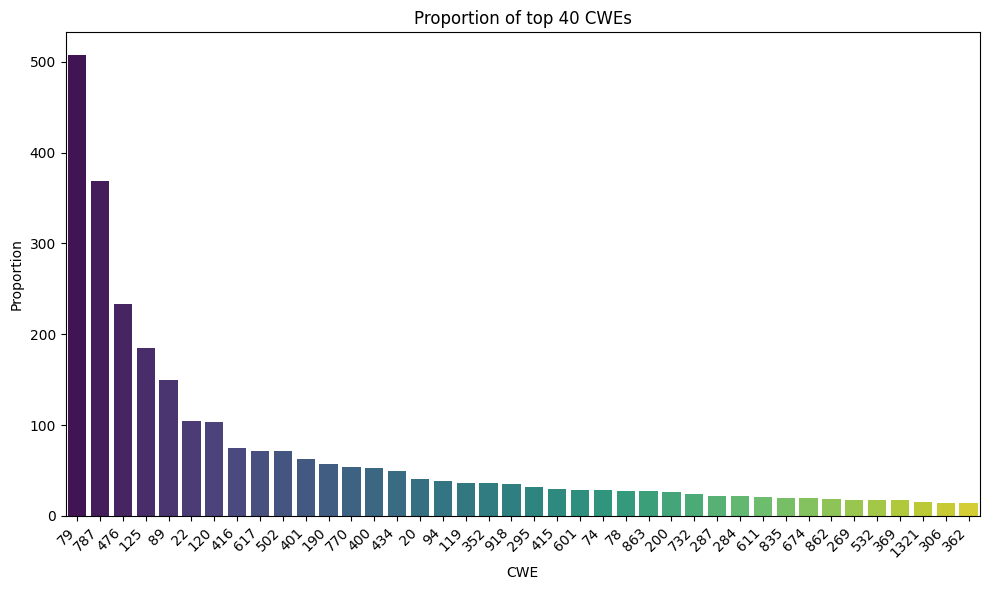

In [63]:
distinct_cwe_count = len(true_pos_large.cve_primary_cwe.value_counts())
cwe_count = len(true_pos_large)
in1003 = len(true_pos_large.loc[true_pos_large.cve_primary_cwe.isin(view1003_df.ID.tolist())])
unique_in_1003 = len(true_pos_large.loc[true_pos_large.cve_primary_cwe.isin(view1003_df.ID.tolist()), 'cve_primary_cwe'].value_counts())
print(f"Number of Samples:\t\t\t{cwe_count}")
print(f"Number of CWEs represented:\t\t{distinct_cwe_count}")
print(f"Portion of CWEs in CWE View-1003\t{100*in1003/cwe_count:.2f}%")
print(f"Portion of unique CWEs in CWE View-1003\t{100*unique_in_1003/distinct_cwe_count:.2f}%")
plot_cwe_dist(true_pos_large, save_path="tmp/cwe_distribution_large.svg")

## Table

In [88]:
import statistics as stat
from prettytable import PrettyTable

def tp_sample_stat_table(cwe_df, small, medium, large):
    cwe_count_small = len(small)
    cwe_count_medium = len(medium)
    cwe_count_large = len(large)
    
    distinct_cwe_count_small = len(small.cve_primary_cwe.value_counts())
    distinct_cwe_count_medium = len(medium.cve_primary_cwe.value_counts())
    distinct_cwe_count_large = len(large.cve_primary_cwe.value_counts())
    
    in1003_small = len(small.loc[small.cve_primary_cwe.isin(cwe_df.ID.tolist())])
    in1003_medium = len(medium.loc[medium.cve_primary_cwe.isin(cwe_df.ID.tolist())])
    in1003_large = len(large.loc[large.cve_primary_cwe.isin(cwe_df.ID.tolist())])

    unique_in_1003_small = len(small.loc[small.cve_primary_cwe.isin(cwe_df.ID.tolist()), 'cve_primary_cwe'].value_counts())
    unique_in_1003_medium = len(medium.loc[medium.cve_primary_cwe.isin(cwe_df.ID.tolist()), 'cve_primary_cwe'].value_counts())
    unique_in_1003_large = len(large.loc[large.cve_primary_cwe.isin(cwe_df.ID.tolist()), 'cve_primary_cwe'].value_counts())
    
    
    table = PrettyTable(
        [
            "Sample Size",
            "Samples (#)",
            "CWEs present (#)",
            "Samples in view 1003 (%)" ,
            "CWEs in view 1003 (%)"
        ]
    )
    table.title = "True Positive Sample Statistics" 
    table.add_rows(
        [
            [
                "Small",
                str(cwe_count_small),
                str(distinct_cwe_count_small),
                "{:.2f}".format(100*in1003_small/cwe_count_small),
                "{:.2f}".format(100*unique_in_1003_small/distinct_cwe_count_small),
            ],
            [
                "Medium",
                str(cwe_count_medium),
                str(distinct_cwe_count_medium),
                "{:.2f}".format(100*in1003_medium/cwe_count_medium),
                "{:.2f}".format(100*unique_in_1003_medium/distinct_cwe_count_medium),
            ],
            [
                "Large",
                str(cwe_count_large),
                str(distinct_cwe_count_large),
                "{:.2f}".format(100*in1003_large/cwe_count_large),
                "{:.2f}".format(100*unique_in_1003_large/distinct_cwe_count_large),
            ],
        ]
    )
    return table


display(tp_sample_stat_table(view1003_df, true_pos, true_pos_medium, true_pos_large))

Sample Size,Samples (#),CWEs present (#),Samples in view 1003 (%),CWEs in view 1003 (%)
Small,296,44,97.97,86.36
Medium,1264,109,98.42,89.91
Large,3147,148,98.16,79.73


In [87]:
import statistics as stat
from prettytable import PrettyTable

def sample_stat_table(cwe_df, small, medium, large):

    sample_dict = {'small': small, 'medium': medium, "large": large}
    for k, v in sample_dict.items() :
        sample_dict[k] = {
            "all": v,
            "true_pos": v[v.gpt_is_relevant & ~v.cve_id.isna()],
            "false_pos": v[v.gpt_is_relevant & v.cve_id.isna()],
            "false_neg": v[~v.gpt_is_relevant & ~v.cve_id.isna()],
            "all_pos": v[v.gpt_is_relevant],
            "all_true": v[~v.cve_id.isna()],
            "all_false": v[v.cve_id.isna()],
        }
    
    for k, v in sample_dict.items() :
        sample_dict[k]['pos_sample_count'] = len(v['all_true']) 
        sample_dict[k]['neg_sample_count'] = len(v['all_false'])
        sample_dict[k]['cwe_count'] = len(v['all_true'].cve_primary_cwe.value_counts())
        sample_dict[k]['in1003'] = len(v['all_true'][v['all_true'].cve_primary_cwe.isin(cwe_df.ID.tolist())])
        sample_dict[k]['unique_in1003'] = len(v['all_true'].loc[v['all_true'].cve_primary_cwe.isin(cwe_df.ID.tolist()), 'cve_primary_cwe'].value_counts())    
    
    table = PrettyTable(
        [
            "Sample Size",
            "Positive Samples (#)",
            "Negative Samples (#)",
            "CWEs present (#)",
            "Samples in view 1003 (%)" ,
            "CWEs in view 1003 (%)"
        ]
    )
    table.title = "Sample Statistics" 
    table.add_rows(
        [
            [
                "Small",
                str(sample_dict["small"]["pos_sample_count"]),
                str(sample_dict["small"]["neg_sample_count"]),
                str(str(sample_dict["small"]["cwe_count"]),),
                "{:.2f}".format(100*sample_dict["small"]["in1003"]/sample_dict["small"]["pos_sample_count"]),
                "{:.2f}".format(100*sample_dict["small"]["unique_in1003"]/sample_dict["small"]["cwe_count"]),
            ],
            [
                "Medium",
                str(sample_dict["medium"]["pos_sample_count"]),
                str(sample_dict["medium"]["neg_sample_count"]),
                str(str(sample_dict["medium"]["cwe_count"]),),
                "{:.2f}".format(100*sample_dict["medium"]["in1003"]/sample_dict["medium"]["pos_sample_count"]),
                "{:.2f}".format(100*sample_dict["medium"]["unique_in1003"]/sample_dict["medium"]["cwe_count"]),
            ],
            [
                "Large",
                str(sample_dict["large"]["pos_sample_count"]),
                str(sample_dict["large"]["neg_sample_count"]),
                str(str(sample_dict["large"]["cwe_count"]),),
                "{:.2f}".format(100*sample_dict["large"]["in1003"]/sample_dict["large"]["pos_sample_count"]),
                "{:.2f}".format(100*sample_dict["large"]["unique_in1003"]/sample_dict["large"]["cwe_count"]),
            ],
        ]
    )
    return table


display(sample_stat_table(view1003_df, gpt_pred_df, test_df, gpt_pred_large_df))

Sample Size,Positive Samples (#),Negative Samples (#),CWEs present (#),Samples in view 1003 (%),CWEs in view 1003 (%)
Small,306,1457,45,98.04,86.67
Medium,1364,5055,114,98.31,88.60
Large,3410,12620,152,98.12,78.95


In [89]:
table = tp_sample_stat_table(view1003_df, true_pos, true_pos_medium, true_pos_large)
table_to_svg(table, "tp_sample_statistics.svg")

In [91]:
table = sample_stat_table(view1003_df, gpt_pred_df, test_df, gpt_pred_large_df)
table_to_svg(table, "sample_statistics.svg")